# 02_Baseline Model: Logistic Regression

In [4]:
import sys
!{sys.executable} -m pip install optuna xgboost lightgbm shap imbalanced-learn scikit-learn pandas numpy matplotlib seaborn joblib

  Using cached optuna-4.8.0-py3-none-any.whl.metadata (17 kB)
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
  Using cached lightgbm-4.6.0-py3-none-win_amd64.whl.metadata (17 kB)
  Using cached alembic-1.18.4-py3-none-any.whl.metadata (7.2 kB)
  Using cached colorlog-6.10.1-py3-none-any.whl.metadata (11 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached mako-1.3.12-py3-none-any.whl.metadata (2.9 kB)
Using cached optuna-4.8.0-py3-none-any.whl (419 kB)
Using cached xgboost-3.2.0-py3-none-win_amd64.whl (101.7 MB)
Using cached lightgbm-4.6.0-py3-none-win_amd64.whl (1.5 MB)
   ---------------------------------------- 0.0/555.9 kB ? eta -:--:--
   ------------------ --------------------- 262.1/555.9 kB ? eta -:--:--
   ---------------------------------------- 555.9/555.9 kB 3.7 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached alembic-1.18.4-py3-none-any.whl (263 kB)
Using cached colorlog-6.10.1-py3-none-any.wh

In [5]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import config as cfg
from src.preprocess  import load_and_prepare, scale
from src.train       import train_lr, tune_threshold, save_model
from src.evaluate    import get_metrics, plot_cm, plot_roc, print_report

print('All imports OK')

All imports OK


In [6]:
data = load_and_prepare()

X_train = data['X_train']
X_val   = data['X_val']
X_test  = data['X_test']
y_train = data['y_train']
y_val   = data['y_val']
y_test  = data['y_test']
spw     = data['spw']       # scale_pos_weight for XGBoost later

print(f'Train shape : {X_train.shape}')
print(f'Val   shape : {X_val.shape}')
print(f'Test  shape : {X_test.shape}')

[load_raw] Loaded 101,371 rows × 16 cols
[clean] Dropped 5,062 pre-season rows → 96,309 remain
[clean] Filled 66 nulls in Compound with 'UNKNOWN'
[encode] Added OHE columns: ['C_HARD', 'C_INTERMEDIATE', 'C_MEDIUM', 'C_SOFT', 'C_UNKNOWN', 'C_WET']
[encode] Added Driver_Freq, Compound_Ordinal
[split] Train  :  44,117 rows  | pit rate = 0.157
[split] Val    :  26,381 rows  | pit rate = 0.343
[split] Test   :  25,811 rows  | pit rate = 0.332
[class_weight] neg=37,178 pos=6,939 → scale_pos_weight=5.358
Train shape : (44117, 18)
Val   shape : (26381, 18)
Test  shape : (25811, 18)


In [ ]:
# Scale-Logistic Regression requires normalised inputs
X_train_s, X_val_s, X_test_s, scaler = scale(X_train, X_val, X_test)

[scale] StandardScaler fitted on train, applied to val + test


In [8]:
lr_model = train_lr(X_train_s, y_train)

[train_lr] Logistic Regression fitted.


In [ ]:
lr_probs = lr_model.predict_proba(X_val_s)[:, 1]
lr_preds = lr_model.predict(X_val_s) #default thhreshold:0.5

lr_results = get_metrics('Logistic Regression', y_val, lr_preds, lr_probs)
print(pd.Series(lr_results))

Model        Logistic Regression
Accuracy                  0.5764
Precision                 0.4385
Recall                    0.8349
F1                         0.575
ROC-AUC                   0.7128
dtype: object


In [10]:
print_report('Logistic Regression', y_val, lr_preds)


  Logistic Regression — Classification Report
              precision    recall  f1-score   support

      No Pit       0.84      0.44      0.58     17326
         Pit       0.44      0.83      0.58      9055

    accuracy                           0.58     26381
   macro avg       0.64      0.64      0.58     26381
weighted avg       0.70      0.58      0.58     26381



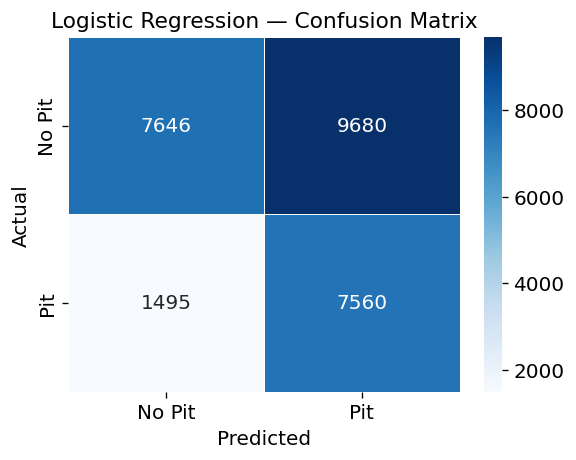

In [11]:
plot_cm(y_val, lr_preds, 'Logistic Regression',
        fname='lr_confusion_matrix.png')

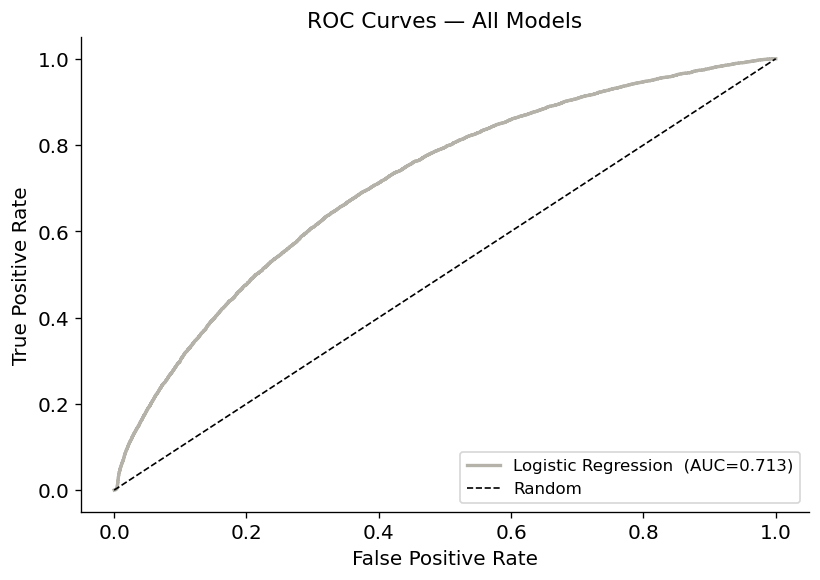

In [12]:
plot_roc([('Logistic Regression', lr_probs)], y_val)

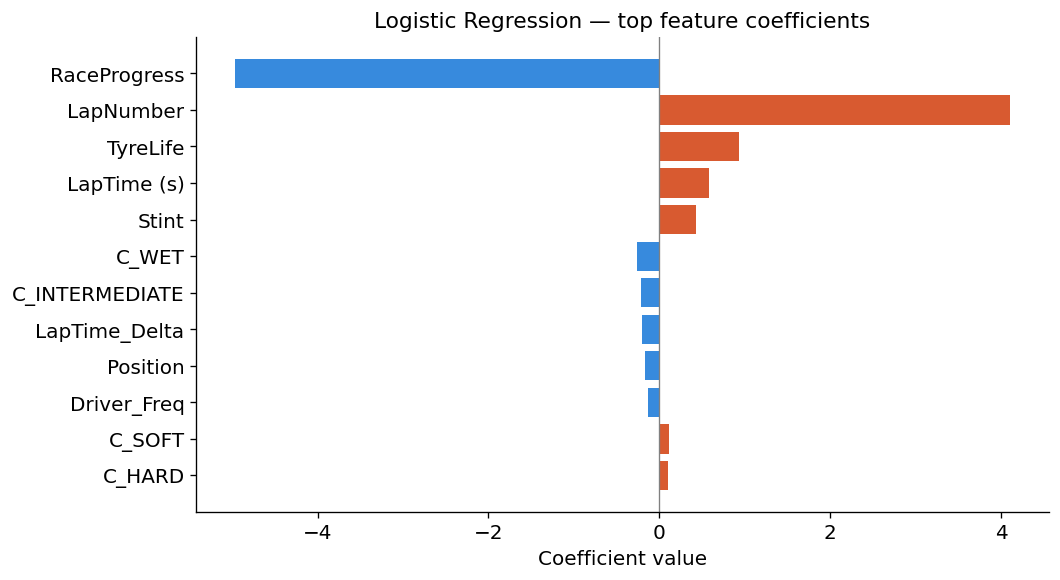

       Feature  Coefficient
  RaceProgress    -4.966660
     LapNumber     4.103081
      TyreLife     0.928406
   LapTime (s)     0.579947
         Stint     0.431678
         C_WET    -0.261590
C_INTERMEDIATE    -0.210642
 LapTime_Delta    -0.207579
      Position    -0.170719
   Driver_Freq    -0.133972
        C_SOFT     0.116781
        C_HARD     0.102816


In [13]:
coef_df = (
    pd.DataFrame({'Feature': cfg.BASE_FEATURES,
                  'Coefficient': lr_model.coef_[0]})
    .sort_values('Coefficient', key=abs, ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(9, 5))
colors = [cfg.COLORS['primary'] if c > 0 else cfg.COLORS['blue']
          for c in coef_df['Coefficient']]
ax.barh(coef_df['Feature'][::-1], coef_df['Coefficient'][::-1],
        color=colors[::-1], edgecolor='none')
ax.axvline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Coefficient value', fontsize=12)
ax.set_title('Logistic Regression — top feature coefficients', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / 'lr_coefficients.png', bbox_inches='tight')
plt.show()
print(coef_df.to_string(index=False))

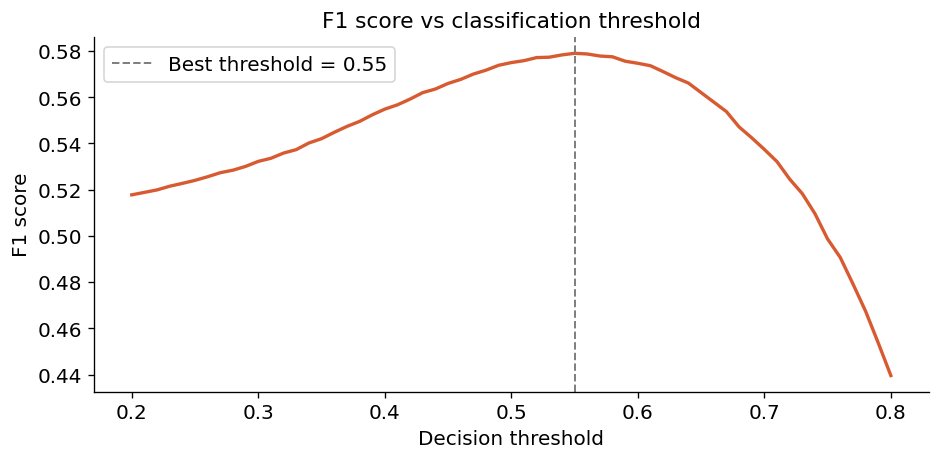


With threshold = 0.55
Model        LR + tuned threshold
Accuracy                   0.6125
Precision                  0.4617
Recall                     0.7764
F1                          0.579
ROC-AUC                    0.7128
dtype: object


In [14]:
#Threshold Tunimg
from src.evaluate import plot_threshold_curve
best_thresh_lr = plot_threshold_curve(lr_model, X_val_s, y_val)

lr_preds_tuned = (lr_probs >= best_thresh_lr).astype(int)
lr_results_tuned = get_metrics(
    'LR + tuned threshold', y_val, lr_preds_tuned, lr_probs
)
print(f'\nWith threshold = {best_thresh_lr:.2f}')
print(pd.Series(lr_results_tuned))

In [ ]:
#Save Model
save_model(lr_model, 'lr_baseline')

import json
(cfg.OUT_DIR / 'lr_results.json').write_text(
    json.dumps(lr_results_tuned, indent=2)
)
print('Saved results and model.')

[save_model] Saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\lr_baseline.joblib
Saved results and model.


## 9. Baseline Summary

| Metric | Score |
|---|---|
| Accuracy | 0.6125 (61.25%) |
| F1 | 0.579 (57.9% `58%) |
| ROC-AUC | 0.7128 (71.28%)|
